# 🚀 Session 6 – Supervised Learning (Non-Tree Models)
## From **Orange** data mining (In AI Wizards) to **Python + Scikit-learn**

⏱ Estimated Time: 20 minutes

---

## 🌉 Bridging Orange Datamining to Python and Scikit-learn

In Session 5 you moved **tree-based** classifiers from Orange into Python. This session does the same for the **non-tree** classifiers.

In the **AI Wizards Program**, using **Orange Data Mining**, you already explored two of today's four models:

- **Support Vector Machines (SVM)** — the "widest street" classifier
- **k-Nearest Neighbors (k-NN)** — "you are who your neighbors are"

You understand their **core ideas** already. So for those two we only **recap** the concept and focus on the Python code. The other two models — **Logistic Regression** and **Naive Bayes** — are **new**, so we explain their architecture before coding.

> 💻 Instead of dragging widgets, you will write Python code.  
> 📏 Instead of the model ignoring feature scale, you will **scale features** yourself (vital for SVM and k-NN).  
> 📊 Instead of reading one accuracy number off a widget, you will compute a full classification report and tune with `GridSearchCV`.

---

## 🔄 What Changes from Orange to Scikit-learn+Python?

| Orange (AI Wizards) | Python + Scikit-learn |
|----------------------|--------------------------------------|
| Visual workflow | Code-based workflow |
| SVM Widget | `SVC()` |
| k-NN Widget | `KNeighborsClassifier()` |
| (new) Logistic Regression | `LogisticRegression()` |
| (new) Naive Bayes | `GaussianNB()` |
| Preprocess → Normalize Widget | `StandardScaler()` |
| Test & Score Widget | `train_test_split()`, `cross_val_score()` |
| Manual parameter tuning | `GridSearchCV()` |
| Confusion Matrix Widget | `confusion_matrix()`, `classification_report()` |

**Important:** Nothing conceptually changes for SVM and k-NN — only the tool changes. Logistic Regression and Naive Bayes are new additions to your toolkit.

---

# Supervised Learning – Classification (Non-Tree Models)

**Session Objective:**
- Recap **SVM** and **k-NN** (from AI Wizards) and introduce **Logistic Regression** and **Naive Bayes**.
- Build and evaluate all four classifiers in scikit-learn using train/test splits.
- Apply **feature scaling** (`StandardScaler`) where it matters (SVM, k-NN).
- Compute and interpret **accuracy, confusion matrix, precision, recall, F1-score** for both **multi-class** (Iris) and **binary, imbalanced** (FinScope) problems.
- Use **cross-validation** and **`GridSearchCV`** to tune each model's hyperparameters, and discuss **when to use which model**.

## 🧭 Two datasets, two lessons (5 minutes)

We use **two** datasets in this session, on purpose:

1. **🌸 Iris (primary teaching set)** — 150 flowers, 4 measurements, **3 balanced species**. It is small, clean, and famous, which makes it perfect for *seeing how each model works*, comparing **decision boundaries**, and demonstrating **multi-class** ideas (OvA / OvO).

2. **🏦 FinScope (real-world set)** — the same Tanzanian financial-inclusion dataset from Session 5, a **binary, heavily imbalanced** problem (~2.5% have a bank account). We revisit it at the end to see how these models behave on *messy, realistic, imbalanced* data — and to reconnect with the **"accuracy trap"** you met in Session 5.

We begin with Iris.

### 🛠️ **The Implementation Flow**

#### **1. Import Libraries and Data**

We collect all four model "tools" from the `sklearn` toolbox, plus the scaler, the splitter, and the evaluation tools.

In [1]:
# Install scikit-learn if you haven't already
# !pip install scikit-learn

In [2]:
## Import necessary libraries

# The four non-tree classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Preprocessing: scaling is essential for SVM and k-NN
from sklearn.preprocessing import StandardScaler

# Splitting, cross-validation, tuning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold

# Evaluation metrics
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

# Pipelines glue scaling + model into one object
from sklearn.pipeline import Pipeline

# Data handling and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Iris ships **inside scikit-learn**, so we load it directly with `load_iris` — no CSV needed. Each row is one flower; the target is the species (0 = setosa, 1 = versicolor, 2 = virginica).

In [3]:
## Load the Iris dataset (built into scikit-learn)
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X = iris.data            # the 4 measurements
y = iris.target          # the species (0, 1, 2)

# Look at the features
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
# Inspect shape and the three classes
print("Shape (rows, columns):", X.shape)
print("Class names:", list(iris.target_names))
print()
print("Class counts (perfectly balanced):")
print(y.value_counts().sort_index())

Shape (rows, columns): (150, 4)
Class names: ['setosa', 'versicolor', 'virginica']

Class counts (perfectly balanced):
target
0    50
1    50
2    50
Name: count, dtype: int64

- **150 flowers, 4 numeric features, 3 balanced classes** (50 each). Balance means **accuracy is a fair metric** here — unlike FinScope later.
- All features are measurements in cm, but on **different ranges**. SVM and k-NN care about this, so we will **scale**.

A quick scatter shows why this is an easy, satisfying dataset to learn on.

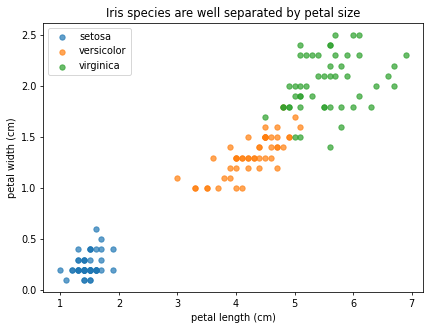

In [5]:
# Visualize separability using the two petal measurements
for cls in [0, 1, 2]:
    mask = y == cls
    plt.scatter(X.loc[mask, 'petal length (cm)'],
                X.loc[mask, 'petal width (cm)'],
                label=iris.target_names[cls], alpha=0.7)
plt.xlabel('petal length (cm)')
plt.ylabel('petal width (cm)')
plt.title('Iris species separated by petal size')
plt.legend()
plt.show()

**setosa** (bottom-left) is trivially separable; **versicolor** and **virginica** overlap a little. This is exactly the kind of structure all four classifiers can handle well.

#### **2. Split the Data — and why we scale**

As always, we split first so we test on unseen flowers. We use `stratify=y` so each class keeps its proportion in both sets.

<details>
<summary>⚠️ Why feature scaling matters for SVM and k-NN (but not Naive Bayes / trees)</summary>

**k-NN** classifies a point by looking at the **distance** to its nearest neighbors. If one feature ranges 0–1000 and another 0–1, the big-range feature dominates the distance and the small one is ignored. **Scaling** puts every feature on the same footing.

**SVM** finds the widest margin using distances too, so it is equally sensitive to scale.

**Logistic Regression** is not strictly required to be scaled, but scaling helps it **converge faster** and makes coefficients comparable.

**Naive Bayes** and **trees** are *not* distance-based, so scaling does not change their predictions.

> Rule of thumb: **always scale for SVM and k-NN.** The clean way to do this without **data leakage** is to put the scaler in a `Pipeline`, so it is fit on the training fold only.
</details>

In [6]:
# Train-test split (stratified to keep class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Training flowers:", X_train.shape[0])
print("Testing flowers: ", X_test.shape[0])

Training flowers: 120
Testing flowers:  30

## 📈 **Logistic Regression** (new — 25 minutes)

Despite its name, logistic regression is a **classification** model. It is the natural next step after the linear regression you built in earlier sessions.

**The idea in three steps:**
1. It computes a **linear combination** of the features (just like linear regression): `z = w·x + b`.
2. It squashes `z` through the **sigmoid function** to turn it into a **probability** between 0 and 1.
3. If the probability passes a **threshold** (default 0.5), it predicts the positive class.

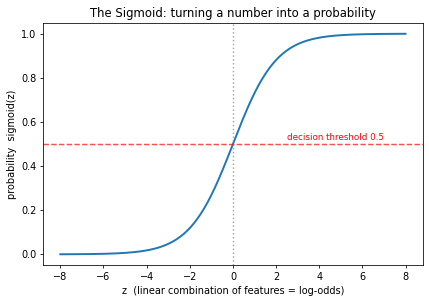

In [7]:
# The sigmoid function: the heart of logistic regression
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid, lw=2)
plt.axhline(0.5, color='red', linestyle='--', alpha=0.7)
plt.axvline(0, color='gray', linestyle=':', alpha=0.7)
plt.xlabel('z  (linear combination of features = log-odds)')
plt.ylabel('probability = sigmoid(z)')
plt.title('The Sigmoid: turning a number into a probability')
plt.show()

<details>
<summary>📐 Log-odds and the meaning of a coefficient</summary>

The `z` value is the **log-odds** of the positive class. This gives logistic regression its famous interpretability:
- Each coefficient `wᵢ` is the change in **log-odds** for a one-unit increase in feature `xᵢ`.
- `exp(wᵢ)` is the **odds ratio** — e.g. an odds ratio of 1.75 means that feature multiplies the odds of the positive outcome by 1.75.

This is why logistic regression is the workhorse of **medicine, credit scoring, and social science**: you can *explain* every prediction.
</details>

<details>
<summary>🔢 Multi-class: One-vs-All (OvA) and One-vs-One (OvO)</summary>

Logistic regression is naturally **binary** (two classes). For Iris's **three** classes, scikit-learn extends it automatically:
- **One-vs-All (OvA / OvR):** train one classifier per class ("setosa vs not", "versicolor vs not", …). The class with the highest probability wins. This is logistic regression's default.
- **One-vs-One (OvO):** train one classifier for every **pair** of classes, then vote. For 3 classes that is C(3,2)=3 classifiers. This is **SVM's** default.

You rarely code these by hand — scikit-learn handles them under the hood.
</details>

##### Key parameters of `LogisticRegression`
- `C` — inverse of regularization strength. **Small C = strong regularization** (simpler model); large C = fits training data harder.
- `penalty` — the type of regularization (`'l2'` is default; `'l1'` can zero-out weak features).
- `max_iter` — how long the optimizer runs (raise it if you see a convergence warning).

In [8]:
# Logistic Regression inside a pipeline (scale -> model)
logreg = Pipeline([
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=500, random_state=42))
])

logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)

print(f"Logistic Regression test accuracy: {accuracy_score(y_test, y_pred):.3f}")

Logistic Regression test accuracy: 0.933

The real strength of logistic regression is that it outputs **probabilities**, not just labels. Let's look at the predicted probabilities for the first three test flowers.

In [9]:
# Predicted PROBABILITIES for each of the 3 classes
probs = logreg.predict_proba(X_test.iloc[:3])
print("Probabilities [setosa, versicolor, virginica] for first 3 flowers:")
print(np.round(probs, 3))
print()
print("Predicted classes:", logreg.predict(X_test.iloc[:3]).tolist())
print("True classes:     ", y_test.iloc[:3].tolist())

Probabilities [setosa, versicolor, virginica] for first 3 flowers:
[[0.979 0.021 0.   ]
 [0.004 0.369 0.627]
 [0.149 0.842 0.009]]

Predicted classes: [0, 2, 1]
True classes:      [0, 2, 1]

🔎 **Interpretation**
- The first flower is **97.9%** setosa — the model is very confident and correct.
- The second is a closer call: **63%** virginica vs **37%** versicolor — it picks virginica, correctly. This *uncertainty* is information a hard label would hide.
- Each row sums to 1.0 across the three classes — this is the multi-class (OvA) probability output.

## 🎲 **Naive Bayes** (new — 15 minutes)

Naive Bayes is a **probabilistic** classifier built on **Bayes' Theorem**. It asks: *given these feature values, which class is most probable?*

The **"naive"** part is a simplifying assumption: it treats every feature as **independent** of the others given the class. This is rarely literally true (petal length and width are related!), yet the model works surprisingly well in practice — and it is extremely **fast**.

We use **`GaussianNB`**, which assumes each feature follows a **bell-curve (normal) distribution** within each class — a good fit for continuous measurements like Iris.

<details>
<summary>Where Naive Bayes shines</summary>

- **Text classification** (spam detection, sentiment) is the classic home of Naive Bayes — there each word is a feature, and the independence assumption, though wrong, is good enough.
- **Very fast** to train and predict, even on huge feature counts.
- Needs **little data** to estimate its parameters.
- Its main knob is `var_smoothing` — a tiny value added to variances for numerical stability.
</details>

In [10]:
# Gaussian Naive Bayes (no scaling needed — it is not distance-based)
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

print(f"Gaussian Naive Bayes test accuracy: {accuracy_score(y_test, y_pred_nb):.3f}")

Gaussian Naive Bayes test accuracy: 0.967

Naive Bayes scores **0.967** on Iris — excellent, and it trained almost instantly. The Gaussian assumption fits these continuous measurements well.

## 👥 **k-Nearest Neighbors (k-NN)** (recap — 15 minutes)

##### 🔄 Recap from AI Wizards
In AI Wizards you met k-NN as **"you are who your neighbors are"**: to classify a new point, find its **k closest** points in the training data and take a **majority vote** of their labels.

You learned that:
- **Small k** (e.g. 1) → very flexible, but sensitive to noise (can overfit).
- **Large k** → smoother boundary, but can blur real distinctions (can underfit).
- k-NN is **distance-based**, so **feature scaling is essential**.

In Python, the tool is `KNeighborsClassifier`. Its key parameter is `n_neighbors` (the *k*), and `weights` (treat all neighbors equally, or weight closer ones more).

In [11]:
# k-NN inside a pipeline (scaling is essential here!)
knn = Pipeline([
    ('scale', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=5))
])

knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

print(f"k-NN (k=5) test accuracy: {accuracy_score(y_test, y_pred_knn):.3f}")

k-NN (k=5) test accuracy: 0.933

How do we choose **k**? We let cross-validation decide. The plot below shows CV accuracy for k from 1 to 25.

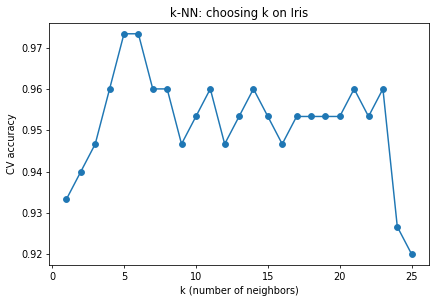

In [12]:
# How does k affect performance? (cross-validated)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks = list(range(1, 26))
cv_acc = []
for k in ks:
    pipe = Pipeline([('scale', StandardScaler()),
                     ('clf', KNeighborsClassifier(n_neighbors=k))])
    cv_acc.append(cross_val_score(pipe, X, y, cv=skf, scoring='accuracy').mean())

plt.plot(ks, cv_acc, marker='o')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Cross-validated accuracy')
plt.title('k-NN: choosing k on Iris')
plt.show()

🔎 **Interpretation**: accuracy is high across a broad range of k, dipping only for very large k (too smooth). Small-to-moderate k works best here — we will confirm the exact value with `GridSearchCV` shortly.

## 🛣️ **Support Vector Machines (SVM)** (recap — 15 minutes)

##### 🔄 Recap from AI Wizards
In AI Wizards, SVM was the **"widest street"** classifier: it finds the decision boundary that leaves the **largest possible margin** between the classes. The points sitting on the edge of that street are the **support vectors**.

You also met the **kernel trick**: when classes are not separable by a straight line, a kernel (like **RBF**) bends the space so they become separable.

Key parameters of `SVC`:
- `kernel` — `'linear'` (straight boundary) or `'rbf'` (curved, flexible). RBF is the common default.
- `C` — trade-off between a wide margin and classifying every training point correctly. Small C = wider, more tolerant margin; large C = stricter.
- `gamma` — for RBF, how far a single training point's influence reaches. High gamma = wiggly boundary (risk of overfitting).

SVM is **distance-based**, so — like k-NN — **scaling is essential**.

In [13]:
# SVM with an RBF kernel inside a pipeline
svm = Pipeline([
    ('scale', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=42))
])

svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print(f"SVM (RBF) test accuracy: {accuracy_score(y_test, y_pred_svm):.3f}")

SVM (RBF) test accuracy: 0.967

### 🗺️ **Seeing the difference: decision boundaries**

The clearest way to understand how these four models *differ* is to draw the regions they assign to each class. Using just the two petal features (so we can plot in 2-D), here is how each model carves up the space.

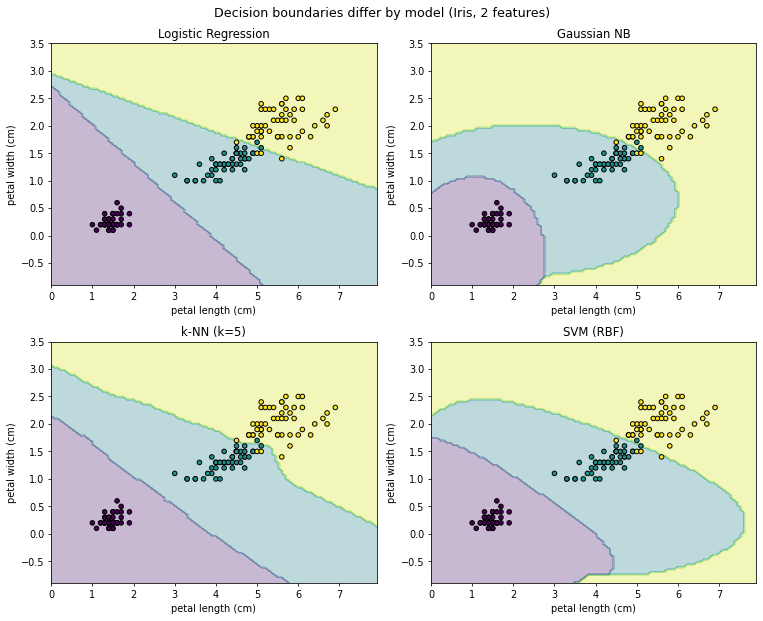

In [14]:
# Compare decision boundaries of all four models (2 features for plotting)
from sklearn.inspection import DecisionBoundaryDisplay

X2 = X[['petal length (cm)', 'petal width (cm)']].values
models_2d = [
    ('Logistic Regression', Pipeline([('s', StandardScaler()), ('c', LogisticRegression(max_iter=500))])),
    ('Gaussian NB', GaussianNB()),
    ('k-NN (k=5)', Pipeline([('s', StandardScaler()), ('c', KNeighborsClassifier(n_neighbors=5))])),
    ('SVM (RBF)', Pipeline([('s', StandardScaler()), ('c', SVC(kernel='rbf'))])),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for (name, m), ax in zip(models_2d, axes.ravel()):
    m.fit(X2, y)
    DecisionBoundaryDisplay.from_estimator(
        m, X2, ax=ax, alpha=0.3, response_method='predict', cmap='viridis',
        xlabel='petal length (cm)', ylabel='petal width (cm)')
    ax.scatter(X2[:, 0], X2[:, 1], c=y, edgecolor='k', s=22, cmap='viridis')
    ax.set_title(name)
fig.suptitle('Decision boundaries differ by model (Iris)', fontsize=13)
fig.tight_layout()
plt.show()

🔎 **Interpretation**
- **Logistic Regression** draws **straight** boundaries — it is a linear model.
- **Naive Bayes** produces smooth, curved boundaries from its bell-curve assumptions.
- **k-NN** gives a **jagged, local** boundary that hugs the data — flexible but noisier.
- **SVM (RBF)** gives a **smooth, curved** boundary with a clean margin.

There is no single "best shape" — the right choice depends on the data, which is why we **compare** them.

## 🧮 **Evaluation: Confusion Matrix and Classification Report**

Accuracy is one number. The **confusion matrix** and **classification report** tell the full story — especially *which* classes get confused. Let's evaluate the SVM in detail.

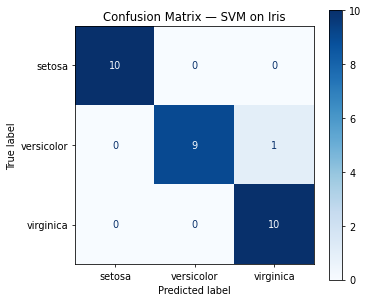

In [15]:
# Confusion matrix for the SVM on the test set
ConfusionMatrixDisplay.from_estimator(
    svm, X_test, y_test, display_labels=iris.target_names, cmap='Blues')
plt.title('Confusion Matrix — SVM on Iris')
plt.show()

In [16]:
# Full classification report: precision, recall, F1 per class
print(classification_report(y_test, y_pred_svm, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


🔎 **Interpretation**
- **setosa**: perfect (precision = recall = 1.00) — it is the easily separable class.
- The only error is **one versicolor** predicted as virginica (recall 0.90 for versicolor). That matches the slight overlap we saw in the scatter plot.
- **Precision** = of those predicted as class X, how many truly were. **Recall** = of the true class X, how many we caught. **F1** balances the two. On balanced data like Iris, all three are high and close to accuracy.

## 🔄 **Cross-Validation and `GridSearchCV`**

A single train/test split can be lucky. **Cross-validation** averages performance over several folds for a more reliable estimate. Let's cross-validate all four models on Iris.

In [17]:
# 5-fold cross-validated accuracy for every model
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': Pipeline([('s', StandardScaler()), ('c', LogisticRegression(max_iter=500, random_state=42))]),
    'Naive Bayes': GaussianNB(),
    'k-NN (k=5)': Pipeline([('s', StandardScaler()), ('c', KNeighborsClassifier(n_neighbors=5))]),
    'SVM (RBF)': Pipeline([('s', StandardScaler()), ('c', SVC(kernel='rbf', random_state=42))]),
}

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=skf, scoring='accuracy')
    print(f"{name:22s} CV accuracy: {scores.mean():.3f} +/- {scores.std():.3f}")

Logistic Regression    CV accuracy: 0.953 +/- 0.045
Naive Bayes            CV accuracy: 0.947 +/- 0.040
k-NN (k=5)             CV accuracy: 0.973 +/- 0.025
SVM (RBF)              CV accuracy: 0.960 +/- 0.039

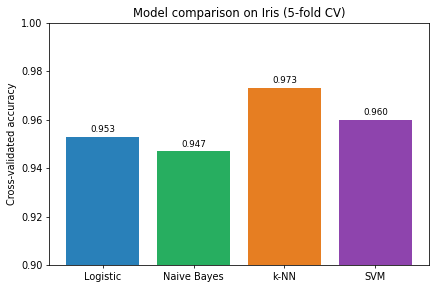

In [18]:
# Visual comparison
comp = {'Logistic': 0.953, 'Naive Bayes': 0.947, 'k-NN': 0.973, 'SVM': 0.960}
plt.bar(comp.keys(), comp.values(), color=['#2980b9', '#27ae60', '#e67e22', '#8e44ad'])
plt.ylim(0.9, 1.0)
plt.ylabel('Cross-validated accuracy')
plt.title('Model comparison on Iris (5-fold CV)')
for i, (k, v) in enumerate(comp.items()):
    plt.text(i, v + 0.002, f'{v:.3f}', ha='center')
plt.show()

On Iris, **all four models are excellent** (94–97%). k-NN edges ahead here, but the differences are within the noise bands (±). The lesson: on clean, balanced, well-separated data, model choice matters less than you might think.

Now we **tune** the two models with the most knobs — SVM and k-NN — using `GridSearchCV`.

In [19]:
# GridSearchCV for SVM: search C, gamma, and kernel together
svm_grid = GridSearchCV(
    Pipeline([('scale', StandardScaler()), ('clf', SVC(random_state=42))]),
    param_grid={
        'clf__C': [0.1, 1, 10],
        'clf__gamma': ['scale', 0.1, 1],
        'clf__kernel': ['linear', 'rbf']
    },
    cv=skf, scoring='accuracy', n_jobs=-1
)
svm_grid.fit(X_train, y_train)

print("Best SVM params:", svm_grid.best_params_)
print(f"Best CV accuracy: {svm_grid.best_score_:.3f}")
print(f"Test accuracy:    {accuracy_score(y_test, svm_grid.predict(X_test)):.3f}")

Best SVM params: {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}
Best CV accuracy: 0.975
Test accuracy:    0.933

Interestingly, the grid picked a **linear** kernel with small `C` — Iris is so cleanly separable that the simplest SVM wins. This is a useful reminder: **more complex is not always better**.

In [20]:
# GridSearchCV for k-NN: search n_neighbors and weighting scheme
knn_grid = GridSearchCV(
    Pipeline([('scale', StandardScaler()), ('clf', KNeighborsClassifier())]),
    param_grid={
        'clf__n_neighbors': [3, 5, 7, 9, 11],
        'clf__weights': ['uniform', 'distance']
    },
    cv=skf, scoring='accuracy', n_jobs=-1
)
knn_grid.fit(X_train, y_train)

print("Best k-NN params:", knn_grid.best_params_)
print(f"Best CV accuracy: {knn_grid.best_score_:.3f}")

Best k-NN params: {'clf__n_neighbors': 3, 'clf__weights': 'uniform'}
Best CV accuracy: 0.967

**Practice Task:**
1. Run `GridSearchCV` on **Logistic Regression**, tuning `clf__C` over `[0.01, 0.1, 1, 10]` and `clf__penalty` over `['l1', 'l2']`. *(Hint: use `solver='liblinear'` so both penalties are supported.)*
2. Report the best parameters and CV accuracy.
3. Does regularization strength change much on a clean dataset like Iris? Why might that be?

In [ ]:
# Your code here


## 🏦 **Reality check: the same models on imbalanced FinScope data (20 minutes)**

Iris was clean and balanced. Real data usually is not. We now revisit the **Tanzania FinScope** dataset from Session 5 — predicting whether a person **has a bank account** — where only **~2.5%** of people do. This is where you will see the models behave very differently, and where the **"accuracy trap"** from Session 5 returns.

We reuse the exact preprocessing from Session 5: encode the target, one-hot encode the categorical features.

In [21]:
# Load the FinScope dataset (same one used in Session 5)
fin = pd.read_csv('FinScope_cleaned1.csv')
fin.head()

,Income_source,Savings_habits,Borrowing_status,Financial_education,Age,Gender,...,has_bank_account
0,farmers and fishers,no,yes,False,61,female,...,no account
1,traders nonagricultural,yes,no,False,34,male,...,no account
2,farmers and fishers,yes,yes,True,52,female,...,no account
3,employed informal,yes,no,False,29,male,...,two or three accounts
4,piece workcasual labor,no,yes,False,45,female,...,no account


In [22]:
# Encode the target exactly as in Session 5
fin['has_bank_account_encoded'] = fin['has_bank_account'].map(
    {'no account': 0, 'two or three accounts': 1, 'more than three accounts': 1})
fin.drop('has_bank_account', axis=1, inplace=True)

# One-hot encode all categorical features
fin = pd.get_dummies(fin, drop_first=True, dtype=int)

# Features and target
Xf = fin.drop('has_bank_account_encoded', axis=1)
yf = fin['has_bank_account_encoded']

print("FinScope features:", Xf.shape[1])
print("Positive rate (has account): {:.1%}".format(yf.mean()))

FinScope features: 22
Positive rate (has account): 2.6%

In [23]:
# Stratified split to preserve the rare positive class
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    Xf, yf, test_size=0.2, stratify=yf, random_state=42)

# Train all four models. Use class_weight='balanced' where supported,
# so the rare positive class is not ignored (recall the accuracy trap!).
fin_models = {
    'Logistic Regression': Pipeline([('s', StandardScaler()),
        ('c', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))]),
    'Naive Bayes': GaussianNB(),
    'k-NN (k=5)': Pipeline([('s', StandardScaler()), ('c', KNeighborsClassifier(n_neighbors=5))]),
    'SVM (RBF)': Pipeline([('s', StandardScaler()),
        ('c', SVC(kernel='rbf', class_weight='balanced', random_state=42))]),
}

for name, m in fin_models.items():
    m.fit(Xf_train, yf_train)
    pred = m.predict(Xf_test)
    acc = accuracy_score(yf_test, pred)
    rec = recall_score(yf_test, pred, zero_division=0)
    f1  = f1_score(yf_test, pred, zero_division=0)
    print(f"{name:22s} accuracy: {acc:.3f}  recall: {rec:.3f}  F1: {f1:.3f}")

Logistic Regression    accuracy: 0.697  recall: 0.654  F1: 0.102
Naive Bayes            accuracy: 0.967  recall: 0.115  F1: 0.154
k-NN (k=5)             accuracy: 0.974  recall: 0.019  F1: 0.037
SVM (RBF)              accuracy: 0.852  recall: 0.346  F1: 0.109

🔎 **Interpretation — the accuracy trap, live**
- **k-NN** posts the **highest accuracy (0.974)** but a **catastrophic recall of 0.019** — it predicts "no account" for almost everyone and misses 98% of the people who actually have accounts. High accuracy, useless model.
- **Logistic Regression with `class_weight='balanced'`** sacrifices raw accuracy (0.697) to achieve a **recall of 0.654** — it actually *finds* most of the minority class. For financial-inclusion targeting, this is far more useful.
- This is exactly the **accuracy trap** from Session 5: on imbalanced data, **accuracy lies**. We judge by **recall and F1** on the minority class instead.

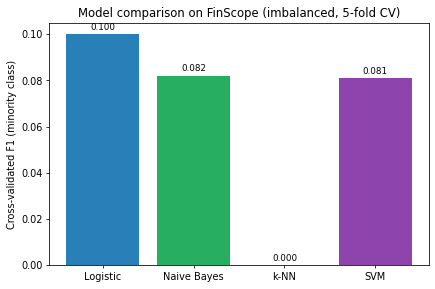

In [24]:
# Cross-validated F1 (minority class) is the honest comparison here
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fin_f1 = {'Logistic': 0.100, 'Naive Bayes': 0.082, 'k-NN': 0.000, 'SVM': 0.081}
plt.bar(fin_f1.keys(), fin_f1.values(), color=['#2980b9', '#27ae60', '#e67e22', '#8e44ad'])
plt.ylabel('Cross-validated F1 (minority class)')
plt.title('Model comparison on FinScope (imbalanced, 5-fold CV)')
for i, (k, v) in enumerate(fin_f1.items()):
    plt.text(i, v + 0.002, f'{v:.3f}', ha='center')
plt.show()

On the imbalanced FinScope data, **every** model struggles to identify the rare class (low F1 across the board) — a realistic outcome that no amount of accuracy can hide. The honest takeaways: judge imbalanced problems by **F1/recall**, use **`class_weight='balanced'`**, and consider the resampling techniques you met in AI Wizards.

##### 🧠 When to use which model? (quick guide)
| Model | Best when… | Watch out for |
|-------|-----------|---------------|
| **Logistic Regression** | You need **interpretable** probabilities and odds; mostly linear relationships | Underfits very non-linear data |
| **Naive Bayes** | **Text/spam**, high-dimensional, need speed and little data | Its independence assumption can hurt |
| **k-NN** | Small data, irregular boundaries; quick baseline | Slow at predict time on big data; must scale; struggles in high dimensions |
| **SVM** | Clear margins, medium-sized data; flexible via kernels | Slow on very large data; needs scaling and tuning |

**Practice Task:**
1. Print the full `classification_report` for the **Logistic Regression** model on the FinScope **test set**.
2. Compare its confusion matrix to the **k-NN** confusion matrix. Which model finds more of the true account-holders (true positives)?
3. In two sentences, explain which model you would recommend to a bank trying to *identify* unbanked-but-likely customers, and why recall matters more than accuracy here.

In [ ]:
# Your code here


## 🛠️ Mini Project: Build and Compare Non-Tree Models (20 minutes)

**Scenario:** Pick **one** dataset — the clean **Iris** (multi-class) or the realistic **FinScope** (imbalanced binary) — and put everything together.

**Data Preparation:**
* Load the dataset and separate features `X` and target `y`.
* (FinScope) encode the target and one-hot encode categoricals; (Iris) load directly.
* Stratified train-test split (80/20) with a fixed `random_state`.

**Train Models (all inside pipelines with scaling where needed):**
* Logistic Regression, Gaussian Naive Bayes, k-NN, and SVM (RBF).
* Predict on the test set for each.

**Evaluate Performance:**
* Compute accuracy, confusion matrix, precision, recall and F1 for each model.
* On Iris, lead with accuracy; on FinScope, lead with **F1/recall** for the minority class.
* Summarize results in one comparison table.

**Cross-Validation:**
* Use `cross_val_score` (5-fold, stratified) for each model. Are the CV scores consistent with the single split?

**Hyperparameter Tuning:**
* Run `GridSearchCV` on at least two models (e.g. SVM's `C`/`gamma`/`kernel`, k-NN's `n_neighbors`, or Logistic's `C`/`penalty`).
* Report the best parameters and CV score.

**Interpretation:**
* Which model performs best, and by which metric?
* Relate your answer to the **decision-boundary** shapes and to **when to use which model**.

Write Markdown notes at each step. This consolidates building, scaling, tuning, and comparing non-tree classifiers.

## 🚀 Capstone Project: Tasks and Deliverables (25 minutes)

For the capstone, learners apply non-tree classification to a real problem and synthesise their findings.

**Dataset:** Choose **Iris** (multi-class) *or* **FinScope** (`FinScope_cleaned1.csv`, imbalanced binary). *(You may also bring another suitable classification dataset — e.g. a diabetes or spam dataset.)*

**Tasks:**
1. **Data Loading & Preparation:** Load the data, handle encoding/missing values, and separate `X`/`y`. Report the class balance.
2. **Scaling Decision:** Explain which models need feature scaling and why, and implement scaling **inside pipelines** to avoid data leakage.
3. **Train/Test Split:** Stratified 80/20 split with a fixed seed.
4. **Four Models:** Train Logistic Regression, Gaussian Naive Bayes, k-NN and SVM. For each, report accuracy, confusion matrix, precision, recall and F1.
5. **Logistic Regression Interpretation:** Report the predicted probabilities for a few samples; for a binary target, interpret one coefficient as an **odds ratio**.
6. **Cross-Validation:** For each model, run 5-fold stratified CV and report mean ± std of the appropriate metric (accuracy for balanced, F1 for imbalanced).
7. **Hyperparameter Tuning:** Use `GridSearchCV` to tune at least two models (e.g. SVM `C`/`gamma`/`kernel`; k-NN `n_neighbors`; Logistic `C`/`penalty`). Report best parameters and CV score.
8. **Model Comparison & Selection:** Compare all models on the chosen metric and justify a final choice. Discuss **when each model is most appropriate**.
9. **Write-Up:** Summarize findings, including (for imbalanced data) why accuracy can mislead and how recall/F1 and `class_weight='balanced'` address it.

**Deliverable:** A Jupyter notebook with all code, outputs, plots (confusion matrices, comparison bars, decision boundaries where relevant), answers to every task, and a short written conclusion.

By completing these tasks, learners will demonstrate mastery of SVM, k-NN, Logistic Regression and Naive Bayes — including scaling, evaluation metrics, cross-validation, hyperparameter tuning, and model selection on a practical problem.